# ============================================================
# CAPITOLO 1: SETUP E CONFIGURAZIONE
# Replica ARX - Hubicka, Marcjasz, Weron (2019)
# ==============================================

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Assicuriamoci che jinja2 sia installato per le tabelle colorate
%pip install jinja2 -q
# --- Configurazione Parametri ---
CSV_PATH = "Dati_progetto_completo.csv"       # [B §3] file dati del progetto
PRICE_COL = "Zonal Price"                     # [B §3] prezzo zona 1
LOAD_COL = "Forecasted Total Load"            # [A §II] z_t = log(load forecast)
TEST_START = pd.Timestamp("2012-12-29")       # [A §II] inizio periodo di test
TEST_END = pd.Timestamp("2013-12-17")         # [A §II] fine periodo di test

# Finestre (Windows) richieste dall'articolo
WINDOWS_ALL = list(range(28, 729, 28))        # Passo 28: 28, 56, ..., 728 (26 finestre)
WINDOWS_SEL = [28, 56, 84, 714, 721, 728]     # AW(28:28:84, 714:7:728)
WINDOWS_STEP_7 = list(range(28, 729, 7))      # Passo 7: 28, 35, ..., 728
WINDOWS_STEP_14 = list(range(28, 729, 14))    # Passo 14: 28, 42, ..., 728

# Unione di tutte le finestre necessarie per la tabella finale
ALL_NEEDED_WINDOWS = sorted(set(WINDOWS_ALL) | set(WINDOWS_SEL) | set(WINDOWS_STEP_7) | set(WINDOWS_STEP_14))

OUTDIR = Path("output_arx_replica")
OUTDIR.mkdir(exist_ok=True)

print("Configurazione completata. Finestre totali da calcolare:", len(ALL_NEEDED_WINDOWS))

Note: you may need to restart the kernel to use updated packages.
Configurazione completata. Finestre totali da calcolare: 101


CAPITOLO 2: CARICAMENTO E PREPARAZIONE DATI

In [15]:
df = pd.read_csv(CSV_PATH)

# Parsing delle date (formato MMDDYYYY H:MM)
df["datetime"] = pd.to_datetime(df["timestamp"], format="%m%d%Y %H:%M")
df = df.sort_values("datetime").reset_index(drop=True)

df["date"]  = df["datetime"].dt.normalize()  # Estrae solo la data
df["hour"]  = df["datetime"].dt.hour         # Estrae l'ora (0-23)
df = df.drop_duplicates(["date", "hour"])    # Rimuove eventuali duplicati

# Creazione matrici Giorni x Ore (Pivot)
price = df.pivot(index="date", columns="hour", values=PRICE_COL).sort_index()
load  = df.pivot(index="date", columns="hour", values=LOAD_COL).sort_index()

price = price.reindex(columns=range(24))       # Forza 24 colonne (0-23)
load  = load.reindex(columns=range(24))        # Forza 24 colonne

# Pulizia: manteniamo solo i giorni con prezzi e load completi
valid = (~price.isna().any(axis=1)) & (~load.isna().any(axis=1))
price = price.loc[valid]
load  = load.loc[valid]

dates = price.index
P = price.values.astype(float)
L = load.values.astype(float)

# Trasformazione Logaritmica
logP = np.log(P)
logL = np.log(L)
n_days, n_hours = logP.shape

print(f"Giorni validi: {n_days}")
print(f"Periodo dati: da {dates[0].date()} a {dates[-1].date()}")

Giorni validi: 1081
Periodo dati: da 2011-01-01 a 2013-12-17


# CAPITOLO 3: COSTRUZIONE DELLE FEATURE ARX

In [16]:
def build_arx_features(logP, logL, dates):
    """
    Costruisce il tensore delle feature F[d, h, k] per il modello ARX.
    k=0: intercetta
    k=1: p_{d-1,h}
    k=2: p_{d-2,h}
    k=3: p_{d-7,h}
    k=4: p_min = min_h p_{d-1,h}
    k=5: z_t = log(load forecast) dello stesso giorno/ora
    k=6,7,8: dummy lunedì, sabato, domenica
    """
    n_days, n_hours = logP.shape
    F = np.full((n_days, n_hours, 9), np.nan)
    
    dow = dates.dayofweek
    is_mon = (dow == 0).astype(float)
    is_sat = (dow == 5).astype(float)
    is_sun = (dow == 6).astype(float)
    
    for d in range(7, n_days):
        pmin_prev = np.min(logP[d-1, :])
        for h in range(n_hours):
            F[d, h, 0] = 1.0
            F[d, h, 1] = logP[d-1, h]
            F[d, h, 2] = logP[d-2, h]
            F[d, h, 3] = logP[d-7, h]
            F[d, h, 4] = pmin_prev
            F[d, h, 5] = logL[d, h]
            F[d, h, 6] = is_mon[d]
            F[d, h, 7] = is_sat[d]
            F[d, h, 8] = is_sun[d]
            
    return F

F = build_arx_features(logP, logL, dates)
print("Tensore delle feature costruito con successo. Dimensioni:", F.shape)

Tensore delle feature costruito con successo. Dimensioni: (1081, 24, 9)


# CAPITOLO 4: STIMA ROLLING WINDOW (BACKTESTING)

In [17]:
test_mask = (dates >= TEST_START) & (dates <= TEST_END)
test_idx = np.where(test_mask)[0]
test_idx = test_idx[test_idx >= 7] # Servono almeno 7 giorni di storico
actual = P[test_idx, :]

print(f"Giorni di test usati: {len(test_idx)}")
print(f"Test da {dates[test_idx[0]].date()} a {dates[test_idx[-1]].date()}")

def forecast_arx_window(F, logP, test_idx, T, n_hours=24):
    """Stima OLS rolling per ogni giorno e ogni ora."""
    n_test = len(test_idx)
    pred = np.full((n_test, n_hours), np.nan)
    
    for j, d in enumerate(test_idx):
        # Gestione della finestra: se d-T < 0, parte da 0
        train_idx = np.arange(max(0, d - T), d)
        
        for h in range(n_hours):
            X = F[train_idx, h, :]
            y = logP[train_idx, h]
            
            # Toglie eventuali righe con NaN (es. primi giorni della serie)
            ok = (~np.isnan(X).any(axis=1)) & (~np.isnan(y))
            
            # Stima OLS
            beta, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)
            
            # Previsione (riportata in scala normale con exp)
            pred[j, h] = np.exp(F[d, h, :] @ beta)
            
    return pred

print("Inizio calcolo previsioni per tutte le finestre...")
preds = {}
for T in ALL_NEEDED_WINDOWS:
    preds[T] = forecast_arx_window(F, logP, test_idx, T)
print("Previsioni completate!")

Giorni di test usati: 353
Test da 2012-12-29 a 2013-12-17
Inizio calcolo previsioni per tutte le finestre...
Previsioni completate!


# CAPITOLO 5: TABELLA MAE (FORMATO ARTICOLO)

In [18]:
# ============================================================
# CAPITOLO 5: TABELLA MAE (CONFRONTO CON L'ARTICOLO - SOLO ARX)
# ============================================================

def mae(pred, actual):
    return np.mean(np.abs(pred - actual))

# Valori ARX estratti dall'articolo (Hubicka et al., 2019)
# Formato: "Nome Modello": [ARX_MAE, ARX_%chng]
paper_data = {
    "Win(28)": [7.758, -10.50],
    "Win(364)": [7.147, -2.35],
    "AW(364,728)": [7.032, -0.72],
    "Win(728)": [6.982, "-"],  # Baseline
    "AW(28:728)": [6.898, 1.20],
    "AW(28:7:728)": [6.891, 1.30],
    "AW(28:14:728)": [6.879, 1.48],
    "AW(28:28:728)": [6.858, 1.78],
    "AW(56,728)": [6.638, 5.05],
    "AW(28,728)": [6.591, 5.76],
    "AW(28:28:84,714:7:728)": [6.514, 6.93],
    "AW(28,56,728)": [6.509, 7.01],
    "AW(28,56,364,728)": [6.501, 7.13],
    "AW(28,56,721,728)": [6.480, 7.46],
}

# Struttura delle righe
table_config = [
    ("Win(28)", "Win", 28),
    ("Win(364)", "Win", 364),
    ("AW(364,728)", "AW", [364, 728]),
    ("Win(728)", "Win", 728),
    ("AW(28:728)", "AW", WINDOWS_ALL),
    ("AW(28:7:728)", "AW", WINDOWS_STEP_7),
    ("AW(28:14:728)", "AW", WINDOWS_STEP_14),
    ("AW(28:28:728)", "AW", WINDOWS_ALL),
    ("AW(56,728)", "AW", [56, 728]),
    ("AW(28,728)", "AW", [28, 728]),
    ("AW(28:28:84,714:7:728)", "AW", WINDOWS_SEL),
    ("AW(28,56,728)", "AW", [28, 56, 728]),
    ("AW(28,56,364,728)", "AW", [28, 56, 364, 728]),
    ("AW(28,56,721,728)", "AW", [28, 56, 721, 728]),
]

data_rows = []
mae_728_nostro = mae(preds[728], actual)

for name, m_type, param in table_config:
    # 1. Calcolo il nostro MAE
    if m_type == "Win":
        p_arr = preds[param]
    else:
        p_arr = np.mean(np.stack([preds[t] for t in param], axis=0), axis=0)
    m_val_nostro = mae(p_arr, actual)
    
    # 2. Calcolo la nostra %chng
    if name == "Win(728)":
        pct_nostro = "-"
    else:
        pct_nostro = ((mae_728_nostro - m_val_nostro) / mae_728_nostro) * 100
        
    # 3. Prendo i valori ARX dell'articolo
    paper_vals = paper_data.get(name, [np.nan, np.nan])
    
    # Aggiungo la riga (solo 5 colonne ora)
    data_rows.append([
        name, 
        m_val_nostro, pct_nostro,       # I nostri dati
        paper_vals[0], paper_vals[1]    # I dati dell'articolo
    ])

# Creazione MultiIndex per le colonne
columns = pd.MultiIndex.from_tuples([
    ("Windows", ""),
    ("Il Nostro ARX", "MAE"),
    ("Il Nostro ARX", "%chng."),
    ("Articolo ARX", "MAE"),
    ("Articolo ARX", "%chng.")
])

df_table = pd.DataFrame(data_rows, columns=columns)

# Funzione per evidenziare in verde i valori migliori
def highlight_best(s):
    if s.name[1] == "MAE":
        is_best = s == s.min()
    elif s.name[1] == "%chng.":
        s_numeric = pd.to_numeric(s, errors='coerce')
        is_best = s == s_numeric.max()
    else:
        return [''] * len(s)
    # Sfondo verde chiaro e testo nero per visibilità su qualsiasi tema
    return ['font-weight: bold; background-color: #90EE90; color: black;' if v else '' for v in is_best]

# Applicazione stile
styled_df = df_table.style.format({
    ("Il Nostro ARX", "MAE"): "{:.3f}",
    ("Il Nostro ARX", "%chng."): lambda x: f"{x:+.2f}%" if isinstance(x, (int, float)) else x,
    ("Articolo ARX", "MAE"): "{:.3f}",
    ("Articolo ARX", "%chng."): lambda x: f"{x:+.2f}%" if isinstance(x, (int, float)) else x,
}, na_rep="").apply(
    highlight_best, subset=[("Il Nostro ARX", "MAE"), ("Articolo ARX", "MAE")]
).set_properties(**{
    'text-align': 'center',
    'border': '1px solid gray',
    'padding': '8px'
}).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'center'), ('border', '1px solid gray'), ('background-color', '#e6e6e6'), ('color', 'black')]},
    {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-weight', 'bold'), ('font-size', '14px'), ('margin-bottom', '10px')]}
]).set_caption("Confronto Prestazioni: Il Nostro Modello ARX vs Articolo Hubicka et al. (2019)")

# Mostra la tabella
display(styled_df)

# Salvataggio
df_table.to_csv(OUTDIR / "tabella_MAE_ARX_confronto.csv", index=False)
with open(OUTDIR / "tabella_MAE_ARX_confronto.html", "w", encoding="utf-8") as f:
    f.write("<html><head><meta charset='utf-8'><style>table {border-collapse: collapse;} th, td {padding: 8px; border: 1px solid gray; text-align: center;} th {background-color: #e6e6e6;}</style></head><body>")
    f.write(styled_df.to_html())
    f.write("</body></html>")

print("Tabella ARX generata e salvata. I valori in verde sono i migliori.")

Tabella ARX generata e salvata. I valori in verde sono i migliori.


# CAPITOLO 6: GRAFICI

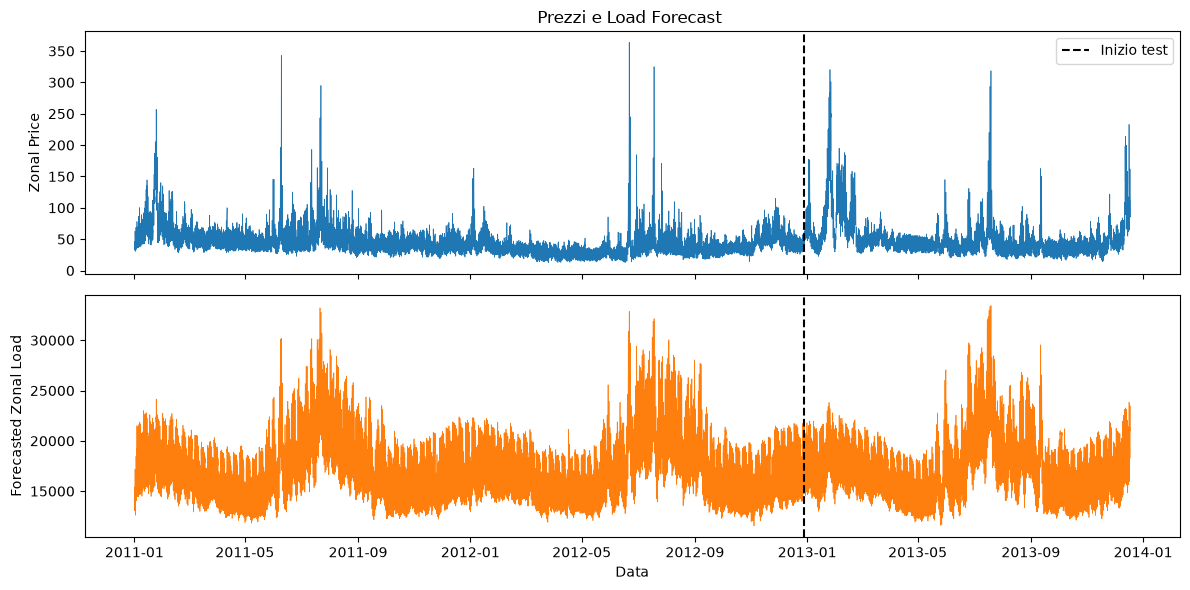

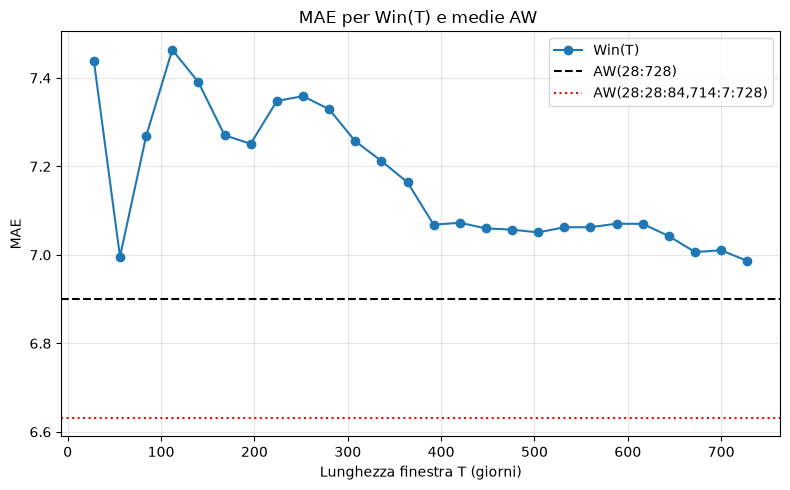

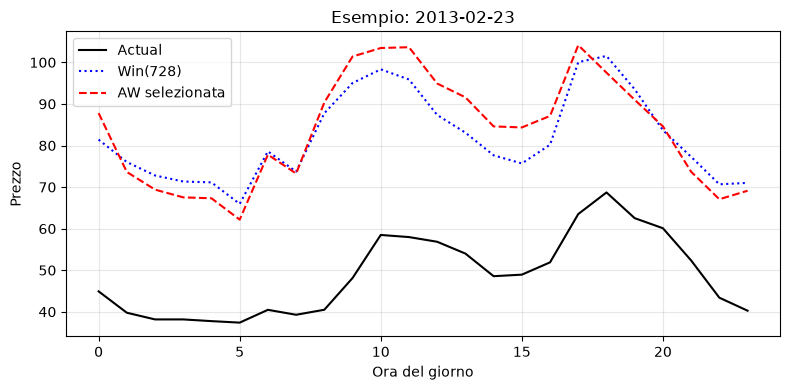

Tutti i grafici sono stati mostrati e salvati nella cartella output_arx_replica/


In [19]:

# --- Grafico 1: Serie Prezzi e Load ---
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(df["datetime"], df[PRICE_COL], linewidth=0.5, color='tab:blue')
axes[0].axvline(TEST_START, color="k", linestyle="--", label="Inizio test")
axes[0].set_ylabel("Zonal Price")
axes[0].set_title("Prezzi e Load Forecast ")
axes[0].legend()

axes[1].plot(df["datetime"], df[LOAD_COL], linewidth=0.5, color='tab:orange')
axes[1].axvline(TEST_START, color="k", linestyle="--")
axes[1].set_ylabel("Forecasted Zonal Load")
axes[1].set_xlabel("Data")
fig.tight_layout()
fig.savefig(OUTDIR / "fig1_prezzi_load.png", dpi=150)
plt.show()

# --- Grafico 2: MAE vs Lunghezza Finestra ---
win_maes = [mae(preds[T], actual) for T in WINDOWS_ALL]
mae_aw_all = mae(np.mean(np.stack([preds[T] for T in WINDOWS_ALL], axis=0), axis=0), actual)
mae_aw_sel = mae(np.mean(np.stack([preds[T] for T in WINDOWS_SEL], axis=0), axis=0), actual)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(WINDOWS_ALL, win_maes, "o-", label="Win(T)")
ax.axhline(mae_aw_all, color="k", linestyle="--", label="AW(28:728)")
ax.axhline(mae_aw_sel, color="r", linestyle=":", label="AW(28:28:84,714:7:728)")
ax.set_xlabel("Lunghezza finestra T (giorni)")
ax.set_ylabel("MAE")
ax.set_title("MAE per Win(T) e medie AW ")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUTDIR / "fig2_MAE_vs_finestra.png", dpi=150)
plt.show()

# --- Grafico 3: Esempio Previsione Test ---
j0 = 56 
pred_aw_sel_full = np.mean(np.stack([preds[T] for T in WINDOWS_SEL], axis=0), axis=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(24), actual[j0, :], "k-", label="Actual")
ax.plot(range(24), preds[728][j0, :], "b:", label="Win(728)")
ax.plot(range(24), pred_aw_sel_full[j0, :], "r--", label="AW selezionata")
ax.set_xlabel("Ora del giorno")
ax.set_ylabel("Prezzo")
ax.set_title(f"Esempio: {dates[test_idx[j0]].date()}")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUTDIR / "fig3_esempio_previsione.png", dpi=150)
plt.show()

print("Tutti i grafici sono stati mostrati e salvati nella cartella output_arx_replica/")